## Wstęp do Uczenia Maszynowego

#### Laboratorium 04


### Zakres laboratorium

- walidacja krzyżowa i dobór hiperparametrów drzewa
- regresja liniowa
- regresja logistyczna
- interpretacja predykcji i współczynników modeli
- wprowadzenie do `Pipeline`


In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, roc_auc_score
from sklearn.model_selection import KFold, RepeatedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm

In [2]:
# Dane wykorzystywane w sekcji o walidacji krzyżowej.
pima_cv = pd.read_csv("../lab02/pima.csv")
X_cv = pima_cv.drop(columns="Outcome")
y_cv = pima_cv["Outcome"]
X_cv_train, X_cv_test, y_cv_train, y_cv_test = train_test_split(
    X_cv, y_cv, test_size=0.3, random_state=123
)


### 1. Dokończenie: walidacja krzyżowa i dobór hiperparametrów

Walidacja krzyżowa pozwala ocenić model wielokrotnie na różnych fragmentach zbioru treningowego. Wyniki CV służą do porównywania modeli i doboru hiperparametrów; zbiór testowy zachowujemy na końcową, jednorazową ocenę wybranego modelu.

### Kroswalidacja (*ang. cross-validation*) a Leave-One-Out

W $k$-krotnej walidacji krzyżowej dane treningowe dzielimy na $k$ części. Model uczymy $k$ razy, za każdym razem walidując go na innej części; końcowy wynik jest średnią wyników z foldów. Leave-One-Out to szczególny przypadek z $k=n$: każdy fold ma jedną obserwację walidacyjną. Wykorzystuje niemal wszystkie dane do uczenia, ale wymaga $n$ dopasowań modelu.


![](https://scikit-learn.org/stable/_images/grid_search_cross_validation.png)

Więcej: https://scikit-learn.org/stable/modules/cross_validation.html


---
##### *Zadanie 1*

Wymień zalety i wady kroswalidacji.


Zalety:


Wady:


---
##### *Zadanie 2*

Korzystając z przygotowanego wyżej zbioru treningowego `pima`, oszacuj jakość drzewa za pomocą 10-krotnej walidacji krzyżowej z miarą `accuracy`. Podaj średnią i odchylenie standardowe wyniku.


In [5]:
# Walidacja krzyżowa wyłącznie na zbiorze treningowym
cv_10 = KFold(n_splits=10, shuffle=True, random_state=123)
model = tree.DecisionTreeClassifier(random_state=123)
scores = cross_val_score(model, X_cv_train, y_cv_train, cv=cv_10, scoring="accuracy")

In [10]:
print("Wyniki walidacji krzyżowej:")
print(f"Wyniki 10x CV: {np.round(scores, 3)}")
print(f"Średnia accuracy: {scores.mean():.3f} ± {scores.std():.3f}")

Wyniki walidacji krzyżowej:
Wyniki 10x CV: [0.667 0.722 0.722 0.759 0.574 0.556 0.704 0.679 0.698 0.623]
Średnia accuracy: 0.670 ± 0.063


---
##### *Zadanie 3*

Na zbiorze treningowym wykonaj 100 powtórzeń 10-krotnej walidacji krzyżowej dla drzewa, używając miary `roc_auc`. Podaj średnią, odchylenie standardowe i narysuj rozkład wyników.


In [23]:
cv_100_10 = RepeatedKFold(n_splits=10, n_repeats=100, random_state=123)
model = tree.DecisionTreeClassifier(random_state=123)
scores = cross_val_score(model, X_cv_train, y_cv_train, cv=cv_100_10, scoring="roc_auc")

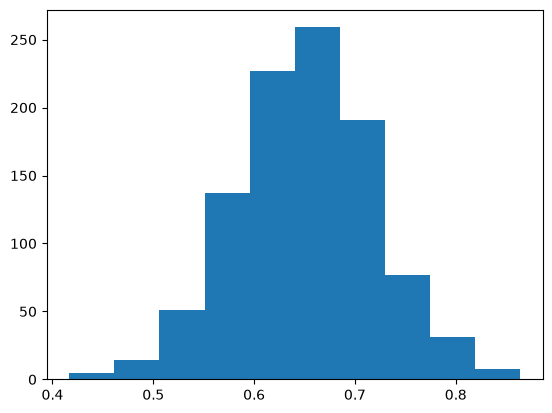

In [25]:
plt.hist(scores);

---
##### *Zadanie 4*

Dla danych `pima` zbadaj zachowanie hiperparametru `max_leaf_nodes` drzewa klasyfikacyjnego w zakresie od 2 do 30. Na danych treningowych i w 5-krotnej CV oblicz `accuracy`, `precision` i `roc_auc`. Przygotuj wizualizację, wybierz wartość według `roc_auc` z CV, a następnie raz oceń wybrany model na zbiorze testowym.

> **Uwaga.** Hiperparametr wybieramy wyłącznie na podstawie wyniku walidacji krzyżowej. Zbiór testowy służy tylko do końcowej oceny wybranego modelu.


In [46]:
cv_5 = KFold(n_splits=5, shuffle=True, random_state=123)

max_leaf_nodes = np.arange(2, 30+1)
scores = {
    "accuracy": [],
    "precision": [],
    "roc_auc": [],
}

for m in tqdm(max_leaf_nodes):
    model = tree.DecisionTreeClassifier(random_state=123, max_leaf_nodes=m)
    for key in scores:
        scores[key].append(np.mean(cross_val_score(model, X_cv_train, y_cv_train, cv=cv_5, scoring=key)))

100%|██████████| 29/29 [00:02<00:00,  9.74it/s]


Text(0, 0.5, 'score')

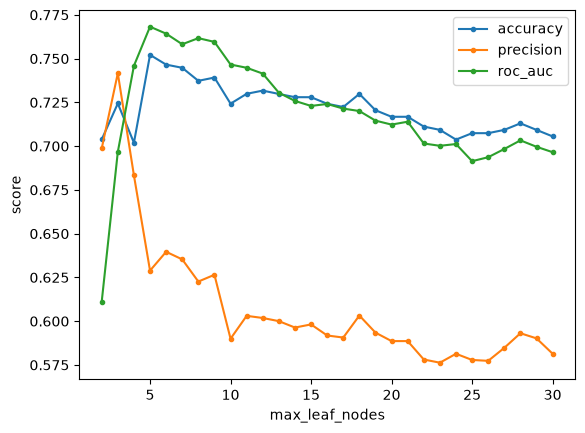

In [47]:
for key in scores:
    plt.plot(max_leaf_nodes, scores[key], label=key, marker=".")
plt.legend()
plt.xlabel("max_leaf_nodes")
plt.ylabel("score")

In [ ]:
model = tree.DecisionTreeClassifier(random_state=123, max_leaf_nodes=5)
model.fit(X_cv_train, y_cv_train)
y_cv_pred = model.predict(X_cv_test)
y_cv_proba = model.predict_proba(X_cv_test)

In [60]:
print(f"Accuracy: {np.round(accuracy_score(y_cv_test, y_cv_pred), 3)}")
print(f"Precision: {np.round(precision_score(y_cv_test, y_cv_pred), 3)}")
print(f"ROC AUC: {np.round(roc_auc_score(y_cv_test, y_cv_proba[:, 1]), 3)}")

Accuracy: 0.753
Precision: 0.657
ROC AUC: 0.809


### 2. Model regresji liniowej

Równanie modelu (w postaci macierzowej)

$$Y = X \beta + \epsilon$$

Gdzie:

- $Y$ – wektor zmiennej objaśnianej (wymiar $n \times 1$)

- $X$ – macierz cech / zmiennych objaśniających (wymiar $n \times (p+1)$, gdzie pierwsza kolumna to same jedynki dla wyrazu wolnego)

- $\beta$ – wektor nieznanych parametrów / współczynników regresji (wymiar $(p+1) \times 1$)

- $\epsilon$ – wektor składników losowych / błędów (wymiar $n \times 1$)

Kluczowe założenia modelu

- wartość oczekiwana błędu: $E(\epsilon) = 0$

- homoskedastyczność (stała wariancja błędów): $Var(\epsilon \vert{} X) = \sigma^2 I$ (gdzie $I$ to macierz jednostkowa)

- brak współliniowości: macierz $X$ ma pełny rząd kolumnowy, co oznacza, że macierz $X^T X$ jest odwracalna


Współczynniki $\beta$ wyznacza się, minimalizując sumę kwadratów reszt ($RSS$):

$$RSS = \epsilon^T \epsilon = (Y - X\beta)^T (Y - X\beta) \to \min_{\beta}.$$

Rozwiązanie tego problemu prowadzi do wzoru analitycznego na estymator współczynników $\hat{\beta}$:$$\hat{\beta} = (X^T X)^{-1} X^T Y.$$

Przewidywane wartości zmiennej objaśnianej ($\hat{Y}$) dla nowych danych oblicza się jako:$$\hat{Y} = X\hat{\beta}.$$

In [61]:
# Wczytujemy zbiór danych do regresji liniowej
hills = pd.read_csv("hills.csv")

Zbiór danych dotyczący szkockich biegów górskich.
- dist – dystans trasy w milach,

- climb – suma przewyższenia w stópach,

- time – rekordowy czas (męski) w godzinach

> https://search.r-project.org/CRAN/refmans/DAAG/html/hills.html

-----
##### *Zadanie 5*

Dla danych `hills.csv`:

a) Narysuj wykres rozproszenia zmiennej *time* od *dist* oraz *time* od *climb*.

b) Oblicz współczynnik korelacji.


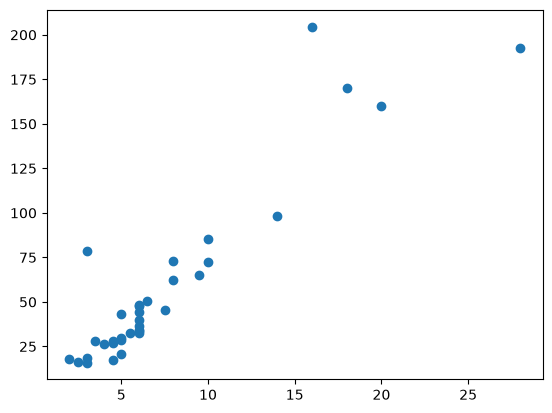

In [71]:
plt.scatter(hills["dist"], hills["time"])
# plt.xscale("log")
# plt.yscale("log")

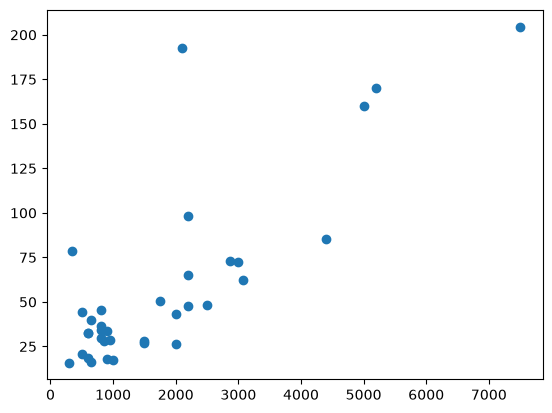

In [72]:
plt.scatter(hills["climb"], hills["time"])
# plt.xscale("log")
# plt.yscale("log")

In [ ]:
hills[["time", "dist", "climb"]].corr()

,time,dist,climb
time,1.000000,0.919589,0.805239
dist,0.919589,1.000000,0.652346
climb,0.805239,0.652346,1.000000


#### Budujemy model regresji liniowej dla pary zmiennych dist i time

In [81]:
model = LinearRegression().fit(hills[["dist"]], hills["time"])

In [82]:
model

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[8.33]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['dist']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-4.841
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


-----
##### *Zadanie 6*

Na wykresie rozproszenia dla `dist` i `time` zaznacz wyestymowaną prostą z modelu liniowego.

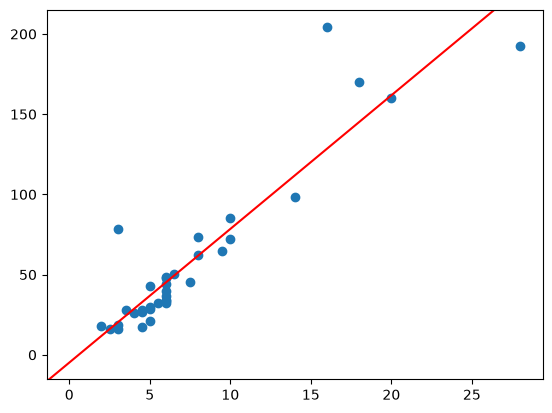

In [86]:
plt.scatter(hills["dist"], hills["time"])
plt.axline((0, model.intercept_), slope=model.coef_[0], color="red")

-----
##### *Zadanie 7*

Zbuduj model regresji liniowej opisujący zależność *time* od *climb*, wyznacz współczynniki, narysuj wykres rozproszenia i zaznacz wyestymowaną prostą.

### 3. Model regresji logistycznej

W modelu regresji liniowej, predykcja jest ciągłą wartością (np. cena domu, wzrost), a model wygląda następująco:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n$$
$\hat{y}$ to przewidywana ciągła wartość.

$\beta_i$ to współczynniki (wagi) modelu.

$x_i$ to zmienne niezależne (cechy).

Ponieważ wartości prognozowane przez model regresji liniowej są rzeczywiste (od $-\infty$ do $+\infty$), a naszym celem jest klasyfikacja, stosujemy funkcję logistyczną jako przekształcenie.

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$
Gdzie $z$ to liniowa: $z = \beta_0 + \beta_1 x_1 + \dots + \beta_n x_n$.

Podstawiając predykcję liniową ($z$) do funkcji logistycznej, otrzymujemy model regresji logistycznej, który zwraca prawdopodobieństwo $P(Y=1|X)$:$$P(Y=1|X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_n x_n)}}$$

W regresji logistycznej istotne jest pojęcie logitu, który jest logarytmem naturalnym ze stosunku szans:$$\text{Logit} = \ln\left(\frac{P(Y=1|X)}{1 - P(Y=1|X)}\right)$$Zauważ, że logit jest równy liniowej kombinacji cech (wynikowi regresji liniowej):$$\ln\left(\frac{P(Y=1|X)}{1 - P(Y=1|X)}\right) = \beta_0 + \beta_1 x_1 + \dots + \beta_n x_n$$To jest powód, dla którego model nazywa się regresją logistyczną - ponieważ regresja jest wykonywana na logarytmie szans (logits).

-----
##### *Zadanie 8*

Przygotuj zbiór danych `SAheart.data` do dalszej pracy.


In [107]:
SAheart = pd.read_csv("SAheart.data")
SAheart

,row.names,sbp,tobacco,ldl,adiposity,famhist,typea,obesity,alcohol,age,chd
0,1,160,12.00,5.73,23.11,Present,49,25.30,97.20,52,1
1,2,144,0.01,4.41,28.61,Absent,55,28.87,2.06,63,1
2,3,118,0.08,3.48,32.28,Present,52,29.14,3.81,46,0
3,4,170,7.50,6.41,38.03,Present,51,31.99,24.26,58,1
4,5,134,13.60,3.50,27.78,Present,60,25.99,57.34,49,1
...,...,...,...,...,...,...,...,...,...,...,...
457,459,214,0.40,5.98,31.72,Absent,64,28.45,0.00,58,0
458,460,182,4.20,4.41,32.10,Absent,52,28.61,18.72,52,1
459,461,108,3.00,1.59,15.23,Absent,40,20.09,26.64,55,0
460,462,118,5.40,11.61,30.79,Absent,64,27.35,23.97,40,0


In [108]:
SAheart.info()

<class 'pandas.DataFrame'>
RangeIndex: 462 entries, 0 to 461
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   row.names  462 non-null    int64  
 1   sbp        462 non-null    int64  
 2   tobacco    462 non-null    float64
 3   ldl        462 non-null    float64
 4   adiposity  462 non-null    float64
 5   famhist    462 non-null    str    
 6   typea      462 non-null    int64  
 7   obesity    462 non-null    float64
 8   alcohol    462 non-null    float64
 9   age        462 non-null    int64  
 10  chd        462 non-null    int64  
dtypes: float64(5), int64(5), str(1)
memory usage: 39.8 KB


In [109]:
SAheart.drop(columns="row.names", inplace=True)

In [110]:
SAheart["famhist"] = SAheart["famhist"].map({"Present": 1, "Absent": 0})

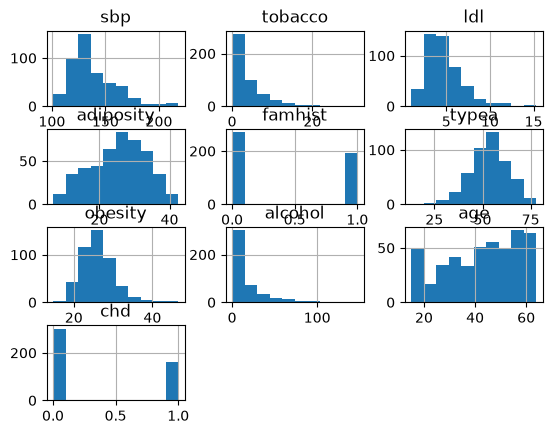

In [112]:
SAheart.hist();

In [113]:
X = SAheart.drop(columns="chd")
y = SAheart["chd"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=123
)

-----
##### *Zadanie 9*

a) Dopasuj model regresji logistycznej do danych `SAheart.data`.

b) Oblicz prawdopodobieństwa przynależności do klasy 1 dla zbioru testowego.

c) Dokonaj predykcji dla obserwacji o wartościach `sbp = 127`, `age = 30`, `alcohol = 0`, `obesity = 25`, `typea = 49`, `famhist = 'Present'`, `tobacco = 0`, `ldl = 4.44`, `adiposity = 18`.

d) Oceń model na zbiorze testowym za pomocą `accuracy` i ROC AUC.


In [125]:
model = LogisticRegression(C=np.inf, max_iter=300).fit(X_train, y_train)
model

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",inf
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",300
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

In [130]:
{k: f"{v:.3}" for k, v in zip(model.feature_names_in_, model.coef_[0])}

{'sbp': '-0.000606',
 'tobacco': '0.11',
 'ldl': '0.182',
 'adiposity': '0.0264',
 'famhist': '0.638',
 'typea': '0.0464',
 'obesity': '-0.0865',
 'alcohol': '0.00111',
 'age': '0.0562'}

In [131]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)

In [ ]:
print(f"Accuracy: {np.round(accuracy_score(y_test, y_pred), 3)}")
print(f"Precision: {np.round(precision_score(y_test, y_pred), 3)}")
print(f"ROC AUC: {np.round(roc_auc_score(y_test, y_proba[:, 1]), 3)}")

Accuracy: 0.705
Precision: 0.628
ROC AUC: 0.727


In [138]:
x = pd.DataFrame({
    "sbp": [127],
    "age": [30],
    "alcohol": [0],
    "obesity": [25],
    "typea": [49],
    "famhist": [1], # ['Present'],
    "tobacco": [0],
    "ldl": [4.44],
    "adiposity": [18],
})
x = x[X.columns]
model.predict_proba(x)

array([[0.88525609, 0.11474391]])

-----
##### *Zadanie 10*

Weźmy pod uwagę dane `earthquake.txt`, które dotyczą klasyfikacji wstrząsów (zmienna *popn*). Zmienne objaśniające to zmienne *body* i *surface* (zmienne sejsmologiczne).

a) Wykonaj wykres dla zmiennych *body* i *surface* z zaznaczeniem przynależności do klas.

b) Dopasuj model regresji logistycznej.

c) Zinterpretuj współczynniki modelu.

> **Uwaga.** Zbiór `earthquake` ma tylko 29 obserwacji. W tym przykładzie dopasowujemy model do całych danych wyłącznie po to, aby zilustrować granicę decyzyjną i interpretację współczynników — nie jest to ocena jakości modelu na nowych danych.


In [24]:
earthquake = pd.read_csv("earthquake.txt", sep=" ")

### 4. Wprowadzenie do `Pipeline`

W praktyce modelowanie zwykle obejmuje więcej niż samo dopasowanie klasyfikatora: na przykład uzupełnianie braków, kodowanie kategorii albo skalowanie zmiennych. Obiekt `Pipeline` łączy takie kroki w jeden estymator. Dzięki temu podczas `fit` transformacje są dopasowywane wyłącznie do zbioru treningowego, a następnie automatycznie stosowane do nowych danych.

W następnym laboratorium wykorzystamy `Pipeline` do pełnego przygotowania danych o różnych typach i z brakującymi wartościami.


#### Przykład: regresja logistyczna w `Pipeline`

Poniżej łączymy standaryzację i regresję logistyczną w jeden obiekt. Po wywołaniu `fit` skaler jest dopasowywany wyłącznie do danych treningowych, a następnie te same kroki są automatycznie stosowane przy `predict` i `predict_proba`.


In [ ]:
logistic_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(C=np.inf, max_iter=300)),
])
logistic_pipeline.fit(X_train, y_train)

pipeline_probabilities = logistic_pipeline.predict_proba(X_test)[:, 1]
print("Accuracy pipeline'u na zbiorze testowym:",
      round(logistic_pipeline.score(X_test, y_test), 3))
print("Pierwsze prawdopodobieństwa:", np.round(pipeline_probabilities[:5], 3))
